# Init:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [ ]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Using GPU for spaCy.
Processing TriviaQA:


Classifying Answers: 100%|███████████████████████████████████████████████████████| 78260/78260 [19:38<00:00, 66.39it/s]


Processing Natural Questions:


Extracting Entities:  24%|████████████▋                                         | 25153/106926 [09:02<28:32, 47.75it/s]

In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 225869 Q-A pairs out of original 272007(83%).


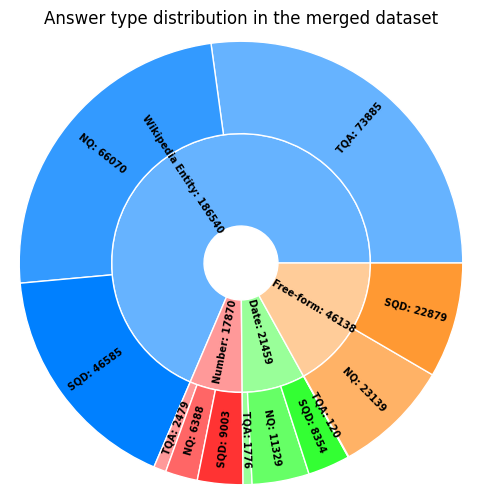

In [38]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

# 3. Group questions: